# Regression Methods — WPPSI-III IQ from Neonatal ECG/HRV

Template for regressing WPPSI-III IQ scores (QIT Full-Scale, QIV Verbal, QIP Performance, …) from neonatal linear + nonlinear HRV features (AuBE cohort, ~189 children, M0 recordings only).

Set ``TARGET_COLUMN`` below to the IQ you want to predict. To compare all IQs at once, use ``model_evaluation.py`` at the project root.

This notebook has been tested in Google Colab and VSCode. It is designed to use the `.env` file in this directory to locate the data files. Make sure to set it up by following the `.env.example` file.

**Research only — not a diagnostic tool.** Health data lives in `data/` and must **never** be committed or shared with AI tools.

See `Group A/dataset.md` for the full data dictionary and merge rules.

### Load data & Initialization

#### imports

In [488]:
# --------------------------------------------------------------
# 1. Imports
# --------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
)

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Pipeline & joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import joblib

# Plotting style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

#### Google colab setup from vscode using colabsync

make sure to connect the colab sync

In [489]:


#loading .env file for notebooks, it looks for .env file in the current working directory
import os
os.chdir("/content")
print("Current working directory: ", os.getcwd())
#list all files in the current working directory
print("Files in current working directory: ", os.listdir(os.getcwd()))

#change the current working directory to the directory of the notebook
os.chdir("/content/international-project/FSIQ-from-ECG/GroupA/Mateo")

print("Current working directory: ", os.getcwd())
print("Files in current working directory: ", os.listdir(os.getcwd()))

%load_ext dotenv
%reload_ext dotenv
%dotenv

#reset environment variables to avoid conflicts
os.environ.pop("DATA_FILE", None)
%dotenv
#create folder for models if it doesn't exist
models_path = os.getenv("MODELS_PATH")
if not os.path.exists(models_path):
    os.makedirs(models_path)
    print(f"Created models directory: {models_path}")

Current working directory:  /content
Files in current working directory:  ['.config', 'international-project', 'sample_data']
Current working directory:  /content/international-project/FSIQ-from-ECG/GroupA/Mateo
Files in current working directory:  ['.env.exemple', '.env', 'method3.ipynb']
The dotenv extension is already loaded. To reload it, use:
  %reload_ext dotenv
Created models directory: /content/international-project/FSIQ-from-ECG/GroupA/Mateo/models


#### loading data from .env file

In [490]:
data_file = os.getenv("DATA_FILE")
non_linearity_file = os.getenv("NON_LINEARITY_FILE")

def load_data(file_path):
    try:
        print(f"Loading data from {file_path}...")
        df = pd.read_csv(file_path, sep="\t", encoding="utf-8-sig", header=None) #change the delimiter to your needs.
        df = df.replace({ #fixing accents, the original file has some encoding issues, so we replace the incorrect characters with the correct ones, we cannot recover automatically
                    "Num�ro": "Numéro",
                    "Diab�te": "Diabète",
                    "Pr�matur�": "Prématuré",
                })
        
        column_names = df.iloc[0].tolist()
        descriptions = df.iloc[1].fillna("").tolist()
        descriptions = ["","",""] + descriptions
        descriptions = descriptions[:len(column_names)] # truncate descriptions to match the number of columns
        df = df.iloc[2:].copy() # remove the first two rows
        df.columns = pd.MultiIndex.from_arrays([column_names, descriptions]) # set the first two rows as column names
        df = df.reset_index(drop=True) # reset the index
        #--- fixing accents
        
        return df
    except Exception as e:
        print(f"Error loading data from {file_path}: {e}")
        return None

# print("data_file: ", data_file)

# raw = pd.read_csv(data_file, sep="\t", encoding="latin-1", header=None) #change the delimiter to your needs.

# column_names = raw.iloc[0].tolist()
# descriptions = raw.iloc[1].tolist()

# descriptions = ["","",""] + descriptions
# descriptions = descriptions[:len(column_names)] # truncate descriptions to match the number of columns

# df = raw.iloc[2:].copy() # remove the first two rows
# df.columns = pd.MultiIndex.from_arrays([column_names, descriptions]) # set the first two rows as column names

df_linear = load_data(data_file)
df_non_linearity = load_data(non_linearity_file)


display(df_linear.head())
display(df_non_linearity.head())

Loading data from /content/international-project/FSIQ-from-ECG/data/HRV_Lineaire_Full.csv...
Loading data from /content/international-project/FSIQ-from-ECG/data/HRV_NonLineaire_Full.csv...


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                 M/F   0/1     0/1 0/1             0/1   
0      1        GAL  11/09/2009    M     1       0   0               0   
1      2        JOG  22/09/2009    M     0       0   0               0   
2      2        JOG  22/09/2009    M     0       0   0               0   
3      2        JOG  22/09/2009    M     0       0   0               0   
4      2        JOG  22/09/2009    M     0       0   0               0   

  Prématuré     SFA  ... TIpsd (IncNight) VLFIpsd (IncNight)  \
        0/1 HIV 3-4  ...               ms               ms^2   
0         0       0  ...                -                  -   
1         0       0  ...                -                  -   
2         0       0  ...                -                  -   
3         0       0  ...                -                  -   
4         0       0  ...                -                  -   

  %VLFIpsd (IncNight) LFIpsd (IncNight) %LFIpsd (IncNight) HFIpsd (IncNight)  \
                 ms^2                 %               ms^2                 %   
0                   -                 -                  -                 -   
1                   -                 -                  -                 -   
2                   -                 -                  -                 -   
3                   -                 -                  -                 -   
4                   -                 -                  -                 -   

  %HFIpsd (IncNight) NaN        
                ms^2   %        
0                  -   -  -  -  
1                  -   -  -  -  
2                  -   -  -  -  
3                  -   -  -  -  
4                  -   -  -  -  

[5 rows x 118 columns]

Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                 M/F   0/1     0/1 0/1             0/1   
0      1        GAL  11/09/2009    M     1       0   0               0   
1      2        JOG  22/09/2009    M     0       0   0               0   
2      2        JOG  22/09/2009    M     0       0   0               0   
3      2        JOG  22/09/2009    M     0       0   0               0   
4      2        JOG  22/09/2009    M     0       0   0               0   

  Prématuré     SFA  ... CE (EntropyNight) CCE (EntropyNight)  \
        0/1 HIV 3-4  ...                 -                  -   
0         0       0  ...                 -                  -   
1         0       0  ...                 -                  -   
2         0       0  ...                 -                  -   
3         0       0  ...                 -                  -   
4         0       0  ...                 -                  -   

  NCCE (EntropyNight) rho (EntropyNight) LZC (Entropy24h) LZC (EntropyDay)  \
                    -                  -                -                -   
0                   -                  -                -                -   
1                   -                  -                -                -   
2                   -                  -                -                -   
3                   -                  -                -                -   
4                   -                  -                -                -   

  LZC (EntropyNight)      NaN        
                   -        -        
0                  -  0.99868  -  -  
1                  -   1.0303  -  -  
2                  -  0.92387  -  -  
3                  -  0.87586  -  -  
4                  -  0.77442  -  -  

[5 rows x 158 columns]

#### loading results

In [491]:
results_file = os.getenv("RESULTS_FILE")


def load_results(file_path):
    try:
        print(f"Loading results from {file_path}...")
        df_results = pd.read_csv(file_path, delimiter="\t", header=None) #change the delimiter to your needs.
        group_headers = df_results.iloc[0].fillna("")
        group_headers = (
            group_headers.replace("", pd.NA)
            .ffill()
            .fillna("")
        )
        column_names = df_results.iloc[1].tolist()
        real_df_results = df_results.iloc[2:].copy() # remove the first two rows
        real_df_results.columns = pd.MultiIndex.from_arrays([group_headers, column_names]) #
        real_df_results = real_df_results.reset_index(drop=True) # reset the index
        return real_df_results
    except Exception as e:
        print(f"Error loading results from {file_path}: {e}")
        return None 

print("results_file: ", results_file)

df_results = load_results(results_file)

display(df_results.head(10))

results_file:  /content/international-project/FSIQ-from-ECG/data/Résultats WPPSI III.csv
Loading results from /content/international-project/FSIQ-from-ECG/data/Résultats WPPSI III.csv...


0                           NS Verb.            NS Perf.      Note composite  \
   N°  NaN         DDN  Age      COM   inf  DIM      CUB  AOB            QIV   
0   1  GAL  11/09/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   
1   2  JOG  22/09/2009   37       10  11.0    9        5   11            102   
2   3  DUL  26/09/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   
3   4  DIM  28/09/2009   36        8   5.0    7        5    9             81   
4   5  ROM  30/09/2009   36       14  13.0    9        7    6            122   
5   6  PRG  03/10/2009   36       10  10.0   11       10   10             99   
6   7  DAA  05/10/2009   36       14  14.0   14        9   14            125   
7   8  DEJ  07/10/2009   36       11  16.0   11        7    8            122   
8   9  CHH  10/10/2009   38       10  10.0    9        7   10             99   
9  10  ZOY  27/07/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   

0  ... Rang percentile      Intervalle de confiance (95%)                     \
   ...             QIT  NCL                           QIV    NaN  QIP    NaN   
0  ...             NaN  NaN                           NaN    NaN  NaN    NaN   
1  ...              37   42                            93  111.0   80  100.0   
2  ...             NaN  NaN                           NaN    NaN  NaN    NaN   
3  ...               7   16                            74   92.0   75   95.0   
4  ...              50   73                           111  128.0   73   93.0   
5  ...              50   58                            90  108.0   90  110.0   
6  ...              91   94                           113  131.0   97  118.0   
7  ...              61   66                           111  128.0   77   98.0   
8  ...              37   42                            90  108.0   83  103.0   
9  ...             NaN  NaN                           NaN    NaN  NaN    NaN   

0                          
   QIT    NaN  NCL    NaN  
0  NaN    NaN  NaN    NaN  
1   87  104.0   89  106.0  
2  NaN    NaN  NaN    NaN  
3   72   88.0   78   95.0  
4   92  108.0   99  117.0  
5   92  108.0   94  111.0  
6  110  126.0  112  129.0  
7   95  112.0   97  114.0  
8   87  104.0   89  106.0  
9  NaN    NaN  NaN    NaN  

[10 rows x 25 columns]

### Preprocessing

#### Target variable

We have to choose between those 4 variables:

- QIT (Quantitative Intelligence Test)
- QIV (Quantitative Intelligence Verbal)
- QIP (Quantitative Intelligence Performance)
- NCL (Nonverbal Cognitive Level)

For this analysis, we will use QIT as the target variable.

In [492]:
TARGET_VARIABLE = "QIT"
AFTER_MERGE_TARGET_VARIABLE = "Note composite_(QIT)"

#### M0 Filterting

In [493]:
passage_positions = [
    i for i, column in enumerate(df_linear.columns)
    if column[0] == "Passage"
] 

print(df_linear.columns[passage_positions])#MultiIndex([('Passage', '-')],)

passage = (
    df_linear.iloc[:, passage_positions[0]]
    .astype("string")
    .str.strip()
) #this is the column that contains the passage information, we will use it to filter the data

df_linear_m0 = df_linear.loc[passage.eq("M0")].copy()

display(df_linear_m0.head())
print(df_linear_m0.shape)

df_non_linearity_m0 = df_non_linearity.loc[passage.eq("M0")].copy()
display(df_non_linearity_m0.head())
print(df_non_linearity_m0.shape)

MultiIndex([('Passage', '-')],
           )


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                  M/F   0/1     0/1 0/1             0/1   
0       1        GAL  11/09/2009    M     1       0   0               0   
1       2        JOG  22/09/2009    M     0       0   0               0   
6       3        DUL  26/09/2009    M     0       0   0               0   
7       4        DIM  28/09/2009    M     0       1   1               0   
12      5        ROM  30/09/2009    M     0       0   0               0   

   Prématuré     SFA  ... TIpsd (IncNight) VLFIpsd (IncNight)  \
         0/1 HIV 3-4  ...               ms               ms^2   
0          0       0  ...                -                  -   
1          0       0  ...                -                  -   
6          0       0  ...                -                  -   
7          0       0  ...                -                  -   
12         0       0  ...                -                  -   

   %VLFIpsd (IncNight) LFIpsd (IncNight) %LFIpsd (IncNight) HFIpsd (IncNight)  \
                  ms^2                 %               ms^2                 %   
0                    -                 -                  -                 -   
1                    -                 -                  -                 -   
6                    -                 -                  -                 -   
7                    -                 -                  -                 -   
12                   -                 -                  -                 -   

   %HFIpsd (IncNight) NaN        
                 ms^2   %        
0                   -   -  -  -  
1                   -   -  -  -  
6                   -   -  -  -  
7                   -   -  -  -  
12                  -   -  -  -  

[5 rows x 118 columns]

(295, 118)


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                  M/F   0/1     0/1 0/1             0/1   
0       1        GAL  11/09/2009    M     1       0   0               0   
1       2        JOG  22/09/2009    M     0       0   0               0   
6       3        DUL  26/09/2009    M     0       0   0               0   
7       4        DIM  28/09/2009    M     0       1   1               0   
12      5        ROM  30/09/2009    M     0       0   0               0   

   Prématuré     SFA  ... CE (EntropyNight) CCE (EntropyNight)  \
         0/1 HIV 3-4  ...                 -                  -   
0          0       0  ...                 -                  -   
1          0       0  ...                 -                  -   
6          0       0  ...                 -                  -   
7          0       0  ...                 -                  -   
12         0       0  ...                 -                  -   

   NCCE (EntropyNight) rho (EntropyNight) LZC (Entropy24h) LZC (EntropyDay)  \
                     -                  -                -                -   
0                    -                  -                -                -   
1                    -                  -                -                -   
6                    -                  -                -                -   
7                    -                  -                -                -   
12                   -                  -                -                -   

   LZC (EntropyNight)      NaN        
                    -        -        
0                   -  0.99868  -  -  
1                   -   1.0303  -  -  
6                   -   1.0188  -  -  
7                   -   1.0247  -  -  
12                  -   1.0242  -  -  

[5 rows x 158 columns]

(295, 158)


#### Remove rows of WSSPI with missing values in the target variable

In [494]:
df_results_clean = df_results.dropna(subset=[("Note composite", TARGET_VARIABLE)]).copy()

print(df_results_clean.shape)
print(df_results.shape)

(195, 25)
(302, 25)


#### Merge linear + nonlinear HRV on Monogramme + DDN + Passage

In [495]:
#convert multiindex to single index for easier merging
df_linear_m0_clean = df_linear_m0.copy()
df_linear_m0_clean.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_linear_m0_clean.columns]

display(df_linear_m0_clean.head())
#print every single column name in the dataframe, not truncated
print(df_linear_m0_clean.columns.to_list())

df_non_linearity_m0_clean = df_non_linearity_m0.copy()
df_non_linearity_m0_clean.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_non_linearity_m0_clean.columns]

#merge
df_merged = pd.merge(
    df_linear_m0_clean,
    df_non_linearity_m0_clean,
    on=["Monogramme", "DDN", "Passage_(-)"],
    how="inner",
)

display(df_merged.head())

,Numéro,Monogramme,DDN,Sexe_(M/F),Tabac_(0/1),Diabète_(0/1),HTA_(0/1),Maturation Pulm_(0/1),Prématuré_(0/1),SFA_(HIV 3-4),...,TIpsd (IncNight)_(ms),VLFIpsd (IncNight)_(ms^2),%VLFIpsd (IncNight)_(ms^2),LFIpsd (IncNight)_(%),%LFIpsd (IncNight)_(ms^2),HFIpsd (IncNight)_(%),%HFIpsd (IncNight)_(ms^2),nan_(%),nan,nan
0,1,GAL,11/09/2009,M,1,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
1,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
6,3,DUL,26/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
7,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,-,-,-,-,-,-,-,-,-,-
12,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-


['Numéro', 'Monogramme', 'DDN', 'Sexe_(M/F)', 'Tabac_(0/1)', 'Diabète_(0/1)', 'HTA_(0/1)', 'Maturation Pulm_(0/1)', 'Prématuré_(0/1)', 'SFA_(HIV 3-4)', 'R�a � la naissance_(LMPV)', 'Pathologie neurologique_(Dilatation ventr)', 'Sortie du service_(Exam neuro normal)', "D�pression: prise d'IRS_(Labilit� cardiaq)", 'Filename_(0/1)', 'Date_(Unit)', 'Recorder_(-)', 'Passage_(-)', 'Total duration_(Hz)', 'Day duration_(-)', 'Night duration', 'Night beginning_(-)', 'Night end_(-)', 'nb RR total_(-)', 'nb RR total day_(-)', 'nb RR total night_(-)', 'nb RR analyzed total_(-)', 'nb RR analyzed day_(-)', 'nb RR analyzed night_(-)', 'nb RR excluded total_(-)', 'nb RR excluded day_(-)', 'nb RR excluded night_(-)', 'nb RR corrected total_(-)', ' nb RR corrected day_(-)', 'nb RR corrected night_(-)', 'Mean RR (TD24h)_(-)', 'Mean HR (TD24h)_(ms)', 'NN20 (TD24h)_(bpm)', 'pcNN20 (TD24h)_(-)', 'NN30 (TD24h)_(%)', 'pcNN30 (TD24h)_(-)', 'NN50 (TD24h)_(%)', 'pcNN50 (TD24h)_(-)', 'SDNN (TD24h)_(%)', 'RMSSD (T

,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,CE (EntropyNight)_(-),CCE (EntropyNight)_(-),NCCE (EntropyNight)_(-),rho (EntropyNight)_(-),LZC (Entropy24h)_(-),LZC (EntropyDay)_(-),LZC (EntropyNight)_(-),nan_(-),nan_y,nan_y
0,1,GAL,11/09/2009,M,1,0,0,0,0,0,...,-,-,-,-,-,-,-,0.99868,-,-
1,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0303,-,-
2,3,DUL,26/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0188,-,-
3,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,-,-,-,-,-,-,-,1.0247,-,-
4,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0242,-,-


#### Merge HRV features with WSSPI data on Monogramme + DDN

In [496]:
#list of columns in df_results_clean
df_results_clean_tmp = df_results_clean.copy()
#df_results_clean_tmp.columns
print(df_results_clean_tmp.columns.to_list())

#for df_results, the monogramme is ('', 'N°'), the DDN is ('', 'DDN'), 
#convert multiindex to single index for easier merging
df_results_clean_tmp.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_results_clean_tmp.columns]

print(df_results_clean_tmp.columns.to_list())

#edit column names in df_results_clean_tmp to match df_merged
df_results_clean_tmp = df_results_clean_tmp.rename(columns={
    "_(nan)": "Monogramme",
    "_(DDN)": "DDN",
})

#merge df_merged with df_results_clean_tmp on Monogramme and DDN
df_merged_full = pd.merge(
    df_merged,
    df_results_clean_tmp,
    on=["Monogramme", "DDN"],
    how="inner",
)

display(df_merged_full.head())
print(df_merged_full.shape)
    

[('', 'N°'), ('', nan), ('', 'DDN'), ('', 'Age'), ('NS Verb.', 'COM'), ('NS Verb.', np.float64(inf)), ('NS Verb.', 'DIM'), ('NS Perf.', 'CUB'), ('NS Perf.', 'AOB'), ('Note composite', 'QIV'), ('Note composite', 'QIP'), ('Note composite', 'QIT'), ('Note composite', 'NCL'), ('Rang percentile', 'QIV'), ('Rang percentile', 'QIP'), ('Rang percentile', 'QIT'), ('Rang percentile', 'NCL'), ('Intervalle de confiance (95%)', 'QIV'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'QIP'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'QIT'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'NCL'), ('Intervalle de confiance (95%)', nan)]
['_(N°)', '_(nan)', '_(DDN)', '_(Age)', 'NS Verb._(COM)', 'NS Verb._(inf)', 'NS Verb._(DIM)', 'NS Perf._(CUB)', 'NS Perf._(AOB)', 'Note composite_(QIV)', 'Note composite_(QIP)', 'Note composite_(QIT)', 'Note composite_(NCL)', 'Rang percentile_(QIV)', 'Rang percentile_(QIP)', 'Rang perce

,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,Rang percentile_(QIT),Rang percentile_(NCL),Intervalle de confiance (95%)_(QIV),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIP),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIT),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(NCL),Intervalle de confiance (95%)_(nan)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,37,42,93,111.0,80,100.0,87,104.0,89,106.0
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,7,16,74,92.0,75,95.0,72,88.0,78,95.0
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,50,73,111,128.0,73,93.0,92,108.0,99,117.0
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,25,58,85,103.0,80,100.0,83,99.0,94,111.0
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,25,73,93,111.0,73,93.0,83,99.0,99,117.0


(189, 296)


#### Drop fully empty feature columns & impute missing values with mean


In [497]:
#drop fully empty feature columns & impute missing values with mean

def drop_empty(df):
    #drop fully empty feature columns 
    df = df.dropna(axis=1, how="all")
    #we know that nan can be represented as a "-" in the data, so we replace "-" with np.nan
    df = df.replace("-", np.nan)
    df = df.replace("", np.nan)
    df = df.replace(" ", np.nan)
    df = df.replace("nan", np.nan)
    df = df.replace("NaN", np.nan)
    df = df.dropna(axis=1, how="all") #drop fully empty feature columns again after replacing "-" with np.nan
    #impute missing values with column mean
    df = df.fillna(df.mean(numeric_only=True))
    return df

df_merged_full_clean = drop_empty(df_merged_full)

display(df_merged_full_clean.head())
print(df_merged_full_clean.shape)
print("missing values in df_merged_full_clean: ", df_merged_full_clean.isnull().sum().sum())

print('columns with how many missing values:')
df_missing = df_merged_full_clean.isnull().sum()
df_missing = df_missing[df_missing > 0]
print(df_missing.sort_values(ascending=False))

/tmp/ipykernel_3950/1018428300.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace("-", np.nan)


,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,Rang percentile_(QIT),Rang percentile_(NCL),Intervalle de confiance (95%)_(QIV),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIP),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIT),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(NCL),Intervalle de confiance (95%)_(nan)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,37,42,93,111.0,80,100.0,87,104.0,89,106.0
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,7,16,74,92.0,75,95.0,72,88.0,78,95.0
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,50,73,111,128.0,73,93.0,92,108.0,99,117.0
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,25,58,85,103.0,80,100.0,83,99.0,94,111.0
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,25,73,93,111.0,73,93.0,83,99.0,99,117.0


(189, 146)
missing values in df_merged_full_clean:  2063
columns with how many missing values:
pLF2(EMD24h)_(ms^2)        182
SampEn (EntropyDay)_(-)    182
LZC (EntropyDay)_(-)       182
CCE (Entropy24h)_(-)       182
DC (ACDC24h)_(ms)          182
                          ... 
1V (Symb24h)_(%)             2
pLF1(EMDDay)_(-)             2
SE (EntropyDay)_(-)          2
NCCE (Entropy24h)_(-)        2
rho (Entropy24h)_(-)         2
Length: 79, dtype: int64


### Feature selection / engineering

#### Remove features with more than 80% missing values


In [498]:
def remove_high_missing(df, threshold=0.8):
    #remove features with more than 80% missing values
    missing = df.isnull().sum() / len(df)
    to_remove = missing[missing > threshold].index
    list_removed = to_remove.tolist()
    print(f"Columns to remove (more than {threshold*100}% missing values): {
list_removed}")
    df = df.drop(columns=to_remove)
    print(f"Removed {len(to_remove)} columns with more than {threshold*100}% missing values.")
    
    print(f"Remaining columns: {df.shape[1]}")  
    return df

df_merged_full_clean_80 = remove_high_missing(df_merged_full_clean, threshold=0.8)

display(df_merged_full_clean_80.head())
print(df_merged_full_clean_80.shape)

print("missing values in df_merged_full_clean_80: ", df_merged_full_clean_80.isnull().sum().sum())

Columns to remove (more than 80.0% missing values): ['Lyapunov (LLEDay)_(-)', 'DC (ACDC24h)_(ms)', '0V (Symb24h)_(ms)', 'pLF2(EMD24h)_(ms^2)', 'pHF1(EMD24h)_(ms^2)', 'AppEn (EntropyDay)_(-)', 'SampEn (EntropyDay)_(-)', 'CE (Entropy24h)_(-)', 'CCE (Entropy24h)_(-)', 'LZC (EntropyDay)_(-)']
Removed 10 columns with more than 80.0% missing values.
Remaining columns: 136


,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,Rang percentile_(QIT),Rang percentile_(NCL),Intervalle de confiance (95%)_(QIV),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIP),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(QIT),Intervalle de confiance (95%)_(nan),Intervalle de confiance (95%)_(NCL),Intervalle de confiance (95%)_(nan)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,37,42,93,111.0,80,100.0,87,104.0,89,106.0
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,7,16,74,92.0,75,95.0,72,88.0,78,95.0
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,50,73,111,128.0,73,93.0,92,108.0,99,117.0
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,25,58,85,103.0,80,100.0,83,99.0,94,111.0
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,25,73,93,111.0,73,93.0,83,99.0,99,117.0


(189, 136)
missing values in df_merged_full_clean_80:  243


#### Correlation analysis & removal of highly correlated features (> 0.95)

columns types with how many missing values:
object     131
float64      5
Name: count, dtype: int64
non-numeric columns:  Index(['Monogramme', 'DDN', 'Sexe_(M/F)_x', 'Passage_(-)',
       'Total duration_(Hz)_x', 'Day duration_(-)', 'Night beginning_(-)',
       'Sexe_(M/F)_y', 'Total duration_(Hz)_y', 'Day duration_(HH:MM:SS)'],
      dtype='object')
non-numeric columns types:  Monogramme                 object
DDN                        object
Sexe_(M/F)_x               object
Passage_(-)                object
Total duration_(Hz)_x      object
Day duration_(-)           object
Night beginning_(-)        object
Sexe_(M/F)_y               object
Total duration_(Hz)_y      object
Day duration_(HH:MM:SS)    object
dtype: object


,Monogramme,DDN,Sexe_(M/F)_x,Passage_(-),Total duration_(Hz)_x,Day duration_(-),Night beginning_(-),Sexe_(M/F)_y,Total duration_(Hz)_y,Day duration_(HH:MM:SS)
0,JOG,22/09/2009,M,M0,24-sept-09,EDF,22:03:28,M,24-sept-09,EDF
1,DIM,28/09/2009,M,M0,01-oct-09,EDF,23:28:30,M,01-oct-09,EDF
2,ROM,30/09/2009,M,M0,03-oct-09,EDF,23:12:26,M,03-oct-09,EDF
3,CLT,16/10/2009,M,M0,20-oct-09,EDF,22:15:16,M,20-oct-09,EDF
4,GUS,21/10/2009,M,M0,23-oct-09,EDF,22:06:23,M,23-oct-09,EDF


columns converted to numeric:  float64    107
int64       29
Name: count, dtype: int64


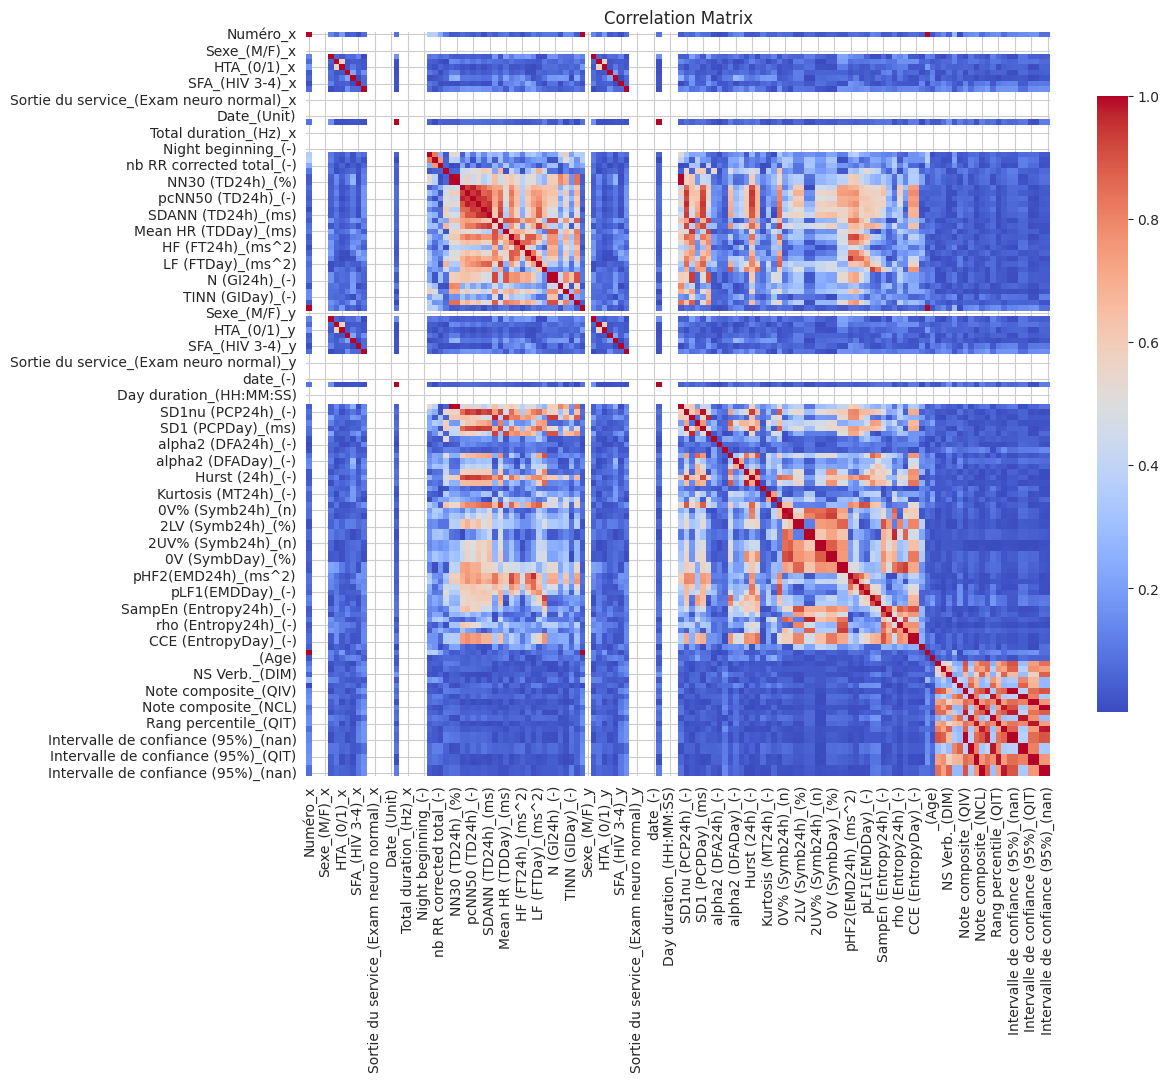

Columns to drop (correlation > 0.95): ['NN30 (TD24h)_(%)', 'pcNN50 (TD24h)_(-)', 'SDNN (TD24h)_(%)', 'SDANN (TD24h)_(ms)', 'N (GI24h)_(-)', 'Numéro_y', 'Tabac_(0/1)_y', 'Diabète_(0/1)_y', 'HTA_(0/1)_y', 'Maturation Pulm_(0/1)_y', 'Prématuré_(0/1)_y', 'SFA_(HIV 3-4)_y', 'R�a � la naissance_(LMPV)_y', 'Recorder_(-)_y', 'SD1SD2 (PCP24h)_(ms)', 'SD1nu (PCP24h)_(-)', 'SD2nu (PCP24h)_(%)', 'SD1 (PCPDay)_(ms)', 'SD2 (PCPDay)_(ms)', 'Beta 1f (Slope24h)_(-)', '1V (Symb24h)_(%)', '2LV (Symb24h)_(%)', '2UV (Symb24h)_(%)', 'MP (Symb24h)_(%)', '0V (SymbDay)_(%)', '1V (SymbDay)_(%)', 'pHF2(EMD24h)_(ms^2)', 'NCCE (Entropy24h)_(-)', 'CCE (EntropyDay)_(-)', '_(N°)', 'Rang percentile_(QIV)', 'Rang percentile_(QIP)', 'Rang percentile_(QIT)', 'Rang percentile_(NCL)', 'Intervalle de confiance (95%)_(QIV)', 'Intervalle de confiance (95%)_(nan)', 'Intervalle de confiance (95%)_(QIP)', 'Intervalle de confiance (95%)_(nan)', 'Intervalle de confiance (95%)_(QIT)', 'Intervalle de confiance (95%)_(nan)', 'Interva

,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,_(Age),NS Verb._(COM),NS Verb._(inf),NS Verb._(DIM),NS Perf._(CUB),NS Perf._(AOB),Note composite_(QIV),Note composite_(QIP),Note composite_(QIT),Note composite_(NCL)
0,2,JOG,22/09/2009,M,0,0.0,0.0,0.0,0,0.0,...,37,10,11.0,9,5,11,102,88,95,97
1,4,DIM,28/09/2009,M,0,1.0,1.0,0.0,0,0.0,...,36,8,5.0,7,5,9,81,82,78,85
2,5,ROM,30/09/2009,M,0,0.0,0.0,0.0,0,0.0,...,36,14,13.0,9,7,6,122,80,100,109
3,12,CLT,16/10/2009,M,1,0.0,0.0,0.0,0,0.0,...,36,10,8.0,11,6,10,93,88,90,103
4,14,GUS,21/10/2009,M,0,0.0,0.0,0.0,0,0.0,...,36,9,12.0,14,6,7,102,80,90,109


In [499]:
#list of columns types with how many missing values
print('columns types with how many missing values:')
df_missing_types = df_merged_full_clean_80.dtypes
df_missing_types = df_missing_types.value_counts()
print(df_missing_types)

#with the analysis above, we can see that columns are usually of type object, and only 5 columns are of type float64. A lot of columns are of type object even though they should be numeric. We will convert all columns to numeric, and if they cannot be converted, we will drop them.
df_merged_full_clean_80_num = df_merged_full_clean_80.apply(pd.to_numeric, errors='coerce')
#we gotta keep columns that are not numeric, so we will create a new dataframe with only the non-numeric columns by selecting the columns that are fully NaN after the conversion to numeric, and we will keep them in a separate dataframe for later use. We will also print the list of non-numeric columns.
df_merged_full_non_numeric = df_merged_full_clean_80_num.isnull().all()
df_merged_full_non_numeric = df_merged_full_clean_80.loc[:, df_merged_full_non_numeric]
non_numeric_columns = df_merged_full_non_numeric.columns
print("non-numeric columns: ", non_numeric_columns)
print("non-numeric columns types: ", df_merged_full_non_numeric.dtypes)

display(df_merged_full_non_numeric.head())

print("columns converted to numeric: ", df_merged_full_clean_80_num.dtypes.value_counts())

def correlation_analysis(df, threshold=0.95):
    #correlation analysis & removal of highly correlated features (> 0.95)
    numeric_df = df.select_dtypes(include=[np.number])
    corr_matrix = numeric_df.corr().abs()
    #plot matrix as a heatmap but only for the ones that are above the threshold, and only for the upper triangle of the matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", fmt=".2f", square=True, cbar_kws={"shrink": 0.8})
    plt.title("Correlation Matrix")
    plt.show()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    print(f"Columns to drop (correlation > {threshold}): {to_drop}")
    df = df.drop(columns=to_drop)
    print(f"Removed {len(to_drop)} columns with correlation > {threshold}.")
    print(f"Remaining columns: {df.shape[1]}")
    return df

df_merged_full_clean_80_corr = correlation_analysis(df_merged_full_clean_80_num, threshold=0.95)

df_merged_full_clean_80_corr[non_numeric_columns] = df_merged_full_non_numeric

display(df_merged_full_clean_80_corr.head())


#### Variance threshold (remove near-zero variance features)



In [500]:
def remove_nearzero_variance(df, threshold=0.01):
    #remove near-zero variance features
    variance = df.var(numeric_only=True)
    to_remove = variance[variance < threshold].index
    list_removed = to_remove.tolist()
    print(f"Columns to remove (variance < {threshold}): {list_removed}")
    df = df.drop(columns=to_remove)
    print(f"Removed {len(to_remove)} columns with variance < {threshold}.")
    print(f"Remaining columns: {df.shape[1]}")
    return df


print("list of columns types:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())
#good news, this has the right types

df_merged_full_clean_80_corr = remove_nearzero_variance(df_merged_full_clean_80_corr, threshold=0.01)

print("list of columns types after removing near-zero variance features:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())


list of columns types:
float64    65
int64      19
object     10
Name: count, dtype: int64
Columns to remove (variance < 0.01): ['Pathologie neurologique_(Dilatation ventr)_x', 'Sortie du service_(Exam neuro normal)_x', "D�pression: prise d'IRS_(Labilit� cardiaq)_x", 'Filename_(0/1)_x', 'Date_(Unit)', 'Recorder_(-)_x', 'Night duration_x', 'Pathologie neurologique_(Dilatation ventr)_y', 'Sortie du service_(Exam neuro normal)_y', "D�pression: prise d'IRS_(Labilit� cardiaq)_y", 'Filename_(0/1)_y', 'date_(-)', 'Night duration_y', 'Centro�d (PCPDay)_(%)', 'alpha2 (DFADay)_(-)', 'H (DFADay)_(-)', 'AC (ACDC24h)_(-)', 'rho (Entropy24h)_(-)', 'CE (EntropyDay)_(-)', 'nan_(-)']
Removed 20 columns with variance < 0.01.
Remaining columns: 74
list of columns types after removing near-zero variance features:
float64    48
int64      16
object     10
Name: count, dtype: int64


#### Lasso/ElasticNet feature selection coefficient screening

In [501]:
def lasso_elasticnet_feature_selection(df, target_variable, alpha=0.01, l1_ratio=0.5):
    #lasso/elasticnet feature selection coefficient screening
    X = df.drop(columns=[target_variable])
    y = df[target_variable]
    
    #impute missing values with mean for numeric columns
    X = X.fillna(X.mean(numeric_only=True))
    
    #standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.select_dtypes(include=[np.number]))
    
    #fit lasso model
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_scaled, y)
    
    #get coefficients
    coef = pd.Series(lasso.coef_, index=X.select_dtypes(include=[np.number]).columns)
    
    #select features with non-zero coefficients
    selected_features = coef[coef != 0].index.tolist()
    
    print(f"Selected features with list of coef: {coef[coef != 0].to_dict()}")
    
    return selected_features

print("list of columns types before lasso/elasticnet feature selection:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())

selected_features = lasso_elasticnet_feature_selection(df_merged_full_clean_80_corr, AFTER_MERGE_TARGET_VARIABLE, alpha=0.01, l1_ratio=0.5)

print("list of selected features after lasso/elasticnet feature selection:")
print(selected_features)

df_merged_lasso_selected = df_merged_full_clean_80_corr[selected_features + [AFTER_MERGE_TARGET_VARIABLE]]

display(df_merged_lasso_selected.head())

print(df_merged_lasso_selected.shape)

list of columns types before lasso/elasticnet feature selection:
float64    48
int64      16
object     10
Name: count, dtype: int64
Selected features with list of coef: {'Numéro_x': -0.02328588740816753, 'Tabac_(0/1)_x': 0.008142727013325572, 'Diabète_(0/1)_x': 0.004135592720846304, 'HTA_(0/1)_x': -0.02514607649661439, 'Maturation Pulm_(0/1)_x': 0.020960048401670688, 'Prématuré_(0/1)_x': 0.007666151322834861, 'SFA_(HIV 3-4)_x': 0.013818898320059066, 'R�a � la naissance_(LMPV)_x': -0.016092882564916776, 'nb RR analyzed total_(-)': -0.07056428664400435, 'pcNN30 (TD24h)_(-)': 0.09708022529818496, 'NN20 (TDDay)_(bpm)': -0.12357866697025408, 'LF (FTDay)_(ms^2)': -0.018241868565167994, 'Y (GI24h)_(ms)': 0.028125432922972895, 'X (GIDay)_(ms)': 0.043727092453429636, 'alpha1 (DFA24h)_(ms/beat)': -0.018046046057875735, 'alpha2 (DFA24h)_(-)': 0.020959121601084468, 'Katz (24h)_(-)': -0.059090538936497926, 'Skewness (MTNight)_(-)': -0.0035125565000304567, 'Kurtosis (MT24h)_(-)': -0.032399622246902

,Numéro_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,R�a � la naissance_(LMPV)_x,nb RR analyzed total_(-),pcNN30 (TD24h)_(-),...,pHF1(EMDDay)_(ms^2),_(Age),NS Verb._(COM),NS Verb._(inf),NS Verb._(DIM),NS Perf._(CUB),NS Perf._(AOB),Note composite_(QIV),Note composite_(QIP),Note composite_(QIT)
0,2,0,0.0,0.0,0.0,0,0.0,0.0,170231,7965.0,...,0.75278,37,10,11.0,9,5,11,102,88,95
1,4,0,1.0,1.0,0.0,0,0.0,0.0,171920,31075.0,...,0.72976,36,8,5.0,7,5,9,81,82,78
2,5,0,0.0,0.0,0.0,0,0.0,0.0,160087,49810.0,...,0.84077,36,14,13.0,9,7,6,122,80,100
3,12,1,0.0,0.0,0.0,0,0.0,0.0,160083,32951.0,...,0.90111,36,10,8.0,11,6,10,93,88,90
4,14,0,0.0,0.0,0.0,0,0.0,0.0,167414,16086.0,...,1.71490,36,9,12.0,14,6,7,102,80,90


(189, 31)


#### Standardization of features on training data

In [502]:
def std_feature_traindata(X_train):
    #standardize features on training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    return X_train_scaled, scaler

df_merged_lasso_selected_numeric = df_merged_lasso_selected.select_dtypes(include=[np.number])
df_merged_lasso_selected_non_numeric = df_merged_lasso_selected.select_dtypes(exclude=[np.number])

target_variable = AFTER_MERGE_TARGET_VARIABLE
try:
    X = df_merged_lasso_selected_numeric.drop(columns=[target_variable])
    y = df_merged_lasso_selected_numeric[target_variable]
    X_train_scaled, scaler = std_feature_traindata(X)
except KeyError as e:
    print(f"Error: {e}")
    
    
nan_counts = X.isna().sum()
#print count and their types
print("Count of NaN values in each column:\n", nan_counts[nan_counts > 0])
print("Count of NaN values in each column types:\n", X.dtypes[nan_counts > 0])




Count of NaN values in each column:
 Diabète_(0/1)_x                7
HTA_(0/1)_x                    2
Maturation Pulm_(0/1)_x        1
SFA_(HIV 3-4)_x                1
R�a � la naissance_(LMPV)_x    2
pcNN30 (TD24h)_(-)             2
NN20 (TDDay)_(bpm)             2
LF (FTDay)_(ms^2)              2
Y (GI24h)_(ms)                 2
X (GIDay)_(ms)                 2
alpha1 (DFA24h)_(ms/beat)      2
alpha2 (DFA24h)_(-)            2
Katz (24h)_(-)                 9
Skewness (MTNight)_(-)         2
Kurtosis (MT24h)_(-)           9
1V% (Symb24h)_(n)              2
2UV% (Symb24h)_(n)             2
pHF1(EMDDay)_(ms^2)            9
dtype: int64
Count of NaN values in each column types:
 Diabète_(0/1)_x                float64
HTA_(0/1)_x                    float64
Maturation Pulm_(0/1)_x        float64
SFA_(HIV 3-4)_x                float64
R�a � la naissance_(LMPV)_x    float64
pcNN30 (TD24h)_(-)             float64
NN20 (TDDay)_(bpm)             float64
LF (FTDay)_(ms^2)              float64
Y

#### Impute missing values with mean on training data


In [503]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train_scaled)

print("nan_counts after imputation: ", np.isnan(X_train_imputed).sum()  )

nan_counts after imputation:  0


#### Save dataset in data folder for future use (locally, .gitignore)

In [504]:
write_path = os.getenv("WRITE_PATH")

#save the dataframe to a csv file in the data folder for future use (locally, .gitignore)

X_train_imputed_df = pd.DataFrame(X_train_imputed, columns=X.columns)
X_and_Y = pd.concat([X_train_imputed_df, y.reset_index(drop=True)], axis=1)

X_and_Y.to_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"), index=False)


### Regression!

#### ElasticNet regression with cross-validation

time with colab = 24s

In [505]:
# parameters

#alpha is the regularization strength, must be a positive float. 

#alpha would be logspace from -4 to 1

alpha_values = np.logspace(-4, 1, 50)

l1_ratio_values = np.linspace(0, 1, 10) #[0.1, 0.3, 0.5, 0.7, 0.9]

models_path = os.getenv("MODELS_PATH")

ElasticNet is a linear regression model that combines L1 and L2 regularization. It is useful when there are multiple features that are correlated with each other. The model has two hyperparameters: alpha (the regularization strength) and l1_ratio (the mix between L1 and L2 regularization).

In [506]:
# model
from sklearn.base import clone

from sklearn.pipeline import make_pipeline
model = ElasticNet()

#import data from the csv file we just saved, and split it into X and y

df_merged_lasso_selected = pd.read_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"))
X_train = df_merged_lasso_selected.drop(columns=[target_variable])
y_train = df_merged_lasso_selected[target_variable]

from sklearn.model_selection import GridSearchCV, KFold

pipeline = make_pipeline(
    StandardScaler(),
    ElasticNet(max_iter=10000, random_state=42)
)

param_grid = {
    "elasticnet__alpha": alpha_values,
    "elasticnet__l1_ratio": l1_ratio_values
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(grid_search.best_params_)
print(-grid_search.best_score_)

joblib.dump(best_model, os.path.join(models_path, "best_elasticnet_model.joblib"))


{'elasticnet__alpha': np.float64(0.028117686979742307), 'elasticnet__l1_ratio': np.float64(1.0)}
0.38000696021135383


['/content/international-project/FSIQ-from-ECG/GroupA/Mateo/models/best_elasticnet_model.joblib']

#### Random Forest regression with cross-validation

time with colab = 1m 21s

In [515]:
#parameters

n_estimators = [200, 500]
max_depth = [None, 3,5,7]
min_samples_split = [5,10,20]
max_features = ["sqrt", "log2"]


In [508]:
model = RandomForestRegressor()

pipeline_rf = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

param_grid_rf = {
    "randomforestregressor__n_estimators": n_estimators,
    "randomforestregressor__max_depth": max_depth,
    "randomforestregressor__min_samples_split": min_samples_split,
    "randomforestregressor__max_features": max_features
}

grid_search_rf = GridSearchCV(
    pipeline_rf,
    param_grid_rf,
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1 #n_jobs=-1 means using all processors, you can change it to a specific number if you want to limit the number of processors used
)

grid_search_rf.fit(X_train, y_train)

best_model_rf = grid_search_rf.best_estimator_
print(grid_search_rf.best_params_)
print(-grid_search_rf.best_score_)

joblib.dump(best_model_rf, os.path.join(models_path, "best_randomforest_model.joblib"))


{'randomforestregressor__max_depth': None, 'randomforestregressor__max_features': 'sqrt', 'randomforestregressor__min_samples_split': 5, 'randomforestregressor__n_estimators': 200}
2.8711918701892403


['/content/international-project/FSIQ-from-ECG/GroupA/Mateo/models/best_randomforest_model.joblib']

#### LightGBM regression with cross-validation

time with colab = 10m 37s

In [520]:
#params
n_estimators = [100, 300]
learning_rate = [0.01, 0.05, 0.1]
max_depth = [3, 5, 7]
min_child_samples = [1,5]
alpha = [0.001, 0.1, 0.5, 1.0]
reg_lambda = [0.0, 0.1, 0.5, 1.0]

In [521]:
#model training

from lightgbm import LGBMRegressor

model = LGBMRegressor(random_state=42, objective='regression', n_jobs=-1, verbosity=-1)

pipeline_lgbm = make_pipeline(
    LGBMRegressor(random_state=42, objective='regression', n_jobs=-1, verbosity=-1)
)

param_grid_lgbm = {
    "lgbmregressor__n_estimators": n_estimators,
    "lgbmregressor__learning_rate": learning_rate,
    "lgbmregressor__max_depth": max_depth,
    "lgbmregressor__min_child_samples": min_child_samples,
    "lgbmregressor__alpha": alpha, #alpha is the L1 regularization term on weights, must be a positive float. 
    "lgbmregressor__reg_lambda": reg_lambda #reg_lambda is the L2 regularization term on weights, must be a positive float. 
}

grid_search_lgbm = GridSearchCV(
    pipeline_lgbm,
    param_grid_lgbm,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

grid_search_lgbm.fit(X_train, y_train)

best_model_lgbm = grid_search_lgbm.best_estimator_
print(grid_search_lgbm.best_params_)
print(-grid_search_lgbm.best_score_)

joblib.dump(best_model_lgbm, os.path.join(models_path, "best_lightgbm_model.joblib"))

{'lgbmregressor__alpha': 0.001, 'lgbmregressor__learning_rate': 0.05, 'lgbmregressor__max_depth': 3, 'lgbmregressor__min_child_samples': 1, 'lgbmregressor__n_estimators': 300, 'lgbmregressor__reg_lambda': 0.1}
1.411937059841352


['/content/international-project/FSIQ-from-ECG/GroupA/Mateo/models/best_lightgbm_model.joblib']

#### XGBoost regression with cross-validation
time with colab = 12min

In [523]:
#params

n_estimators = [100, 300]
learning_rate = [0.01, 0.05, 0.1]
max_depth = [3, 5, 7]
min_child_weight = [1, 5]
subsample = [0.8, 1.0]
colsample_bytree = [0.8, 1.0]
reg_alpha = [0.0,0.1,1.0]
reg_lambda = [0.1,1.0,10.0]

In [525]:
#model training

from xgboost import XGBRegressor

pipeline_xgb = make_pipeline(
    XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1, verbosity=0, eval_metric='mae')
)

param_grid_xgb = {
    "xgbregressor__n_estimators": n_estimators,
    "xgbregressor__learning_rate": learning_rate,
    "xgbregressor__max_depth": max_depth,
    "xgbregressor__min_child_weight": min_child_weight,
    "xgbregressor__subsample": subsample,
    "xgbregressor__colsample_bytree": colsample_bytree,
    "xgbregressor__reg_alpha": reg_alpha,
    "xgbregressor__reg_lambda": reg_lambda,
}

grid_search_xgb = GridSearchCV(
    pipeline_xgb,
    param_grid_xgb,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_xgb.fit(X_train, y_train)

best_model_xgb = grid_search_xgb.best_estimator_
print(grid_search_xgb.best_params_)
print(-grid_search_xgb.best_score_)

joblib.dump(best_model_xgb, os.path.join(models_path, "best_xgboost_model.joblib"))

{'xgbregressor__colsample_bytree': 1.0, 'xgbregressor__learning_rate': 0.05, 'xgbregressor__max_depth': 3, 'xgbregressor__min_child_weight': 1, 'xgbregressor__n_estimators': 300, 'xgbregressor__reg_alpha': 0.0, 'xgbregressor__reg_lambda': 0.1, 'xgbregressor__subsample': 0.8}
1.2979724168777467


['/content/international-project/FSIQ-from-ECG/GroupA/Mateo/models/best_xgboost_model.joblib']

#### Support Vector Regression (SVR) with cross-validation

time with colab = 50s

In [527]:
#params

C = [0.1, 1, 10, 100]
epsilon = [0.01, 0.1, 1.0]
kernel = ['rbf', 'linear']
gamma = ['scale', 'auto']

In [529]:
#model training

from sklearn.svm import SVR

pipeline_svr = make_pipeline(
    StandardScaler(),
    SVR()
)

param_grid_svr = {
    "svr__C": C,
    "svr__epsilon": epsilon,
    "svr__kernel": kernel,
    "svr__gamma": gamma
}

grid_search_svr = GridSearchCV(
    pipeline_svr,
    param_grid_svr,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    error_score='raise'
)

grid_search_svr.fit(X_train, y_train)

best_model_svr = grid_search_svr.best_estimator_
print(grid_search_svr.best_params_)
print(-grid_search_svr.best_score_)

joblib.dump(best_model_svr, os.path.join(models_path, "best_svr_model.joblib"))

{'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}
0.38949975889206145


['/content/international-project/FSIQ-from-ECG/GroupA/Mateo/models/best_svr_model.joblib']

#### Summary of results

|Model|Time|best params|MAR|
|---|---|---|---|
|ElasticNet|24s|